In [103]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, average_precision_score, fbeta_score
import optuna
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv("../data/processed/dataset_80_20_normalized_tcr_with_cohort.csv")

In [104]:
# Variable independiente es immunogenicity y me quedo solo con las variables numericas
X = df.select_dtypes(include=['float64', 'int64']).drop(columns=['immunogenicity','mut_is_binding_pos','bestWTMatchType_I','DAI_MixMHC_mbp','mutant_rank'])
y = df['immunogenicity']

# Normalización de características
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



In [105]:
# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y.values, test_size=0.2, random_state=42, stratify=y)

### Empezamos a definir el modelo y pytorch

In [106]:
# Convertir a tensores de PyTorch
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

In [107]:
class ImprovedMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout_rate=0.3):
        super(ImprovedMLP, self).__init__()
        layers = []
        prev_dim = input_dim
        
        for i, hidden_dim in enumerate(hidden_dims):
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.LeakyReLU(0.1),
                nn.Dropout(dropout_rate)
            ])
            prev_dim = hidden_dim
        
        # Capa final sin dropout
        layers.append(nn.Linear(prev_dim, 1))
        self.network = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.network(x)

In [108]:
class EarlyStopping:
    def __init__(self, patience=10, delta=0.001):
        self.patience = patience
        self.delta = delta
        self.best_score = None
        self.epochs_no_improve = 0
        self.early_stop = False
        
    def __call__(self, val_auc):
        if self.best_score is None:
            self.best_score = val_auc
        elif val_auc < self.best_score + self.delta:
            self.epochs_no_improve += 1
            if self.epochs_no_improve >= self.patience:
                self.early_stop = True
        else:
            self.best_score = val_auc
            self.epochs_no_improve = 0
        return self.early_stop

In [109]:
def evaluate_model(model, data_loader, device):
    """Evaluar modelo y retornar AUC-ROC y AUC-PR"""
    model.eval()
    all_labels = []
    all_outputs = []
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = torch.sigmoid(model(inputs))
            all_labels.extend(labels.cpu().numpy())
            all_outputs.extend(outputs.cpu().numpy())
    
    try:
        auc_roc = roc_auc_score(all_labels, all_outputs)
        auc_pr = average_precision_score(all_labels, all_outputs)
    except ValueError:
        auc_roc, auc_pr = 0.0, 0.0
        
    return auc_roc, auc_pr, all_labels, all_outputs

In [110]:
def objective_improved(trial):
    # ===== HIPERPARÁMETROS EXPANDIDOS =====
    n_layers = trial.suggest_int('n_layers', 1, 5)
    hidden_dims = []
    
    dim_strategy = trial.suggest_categorical('dim_strategy', ['decreasing', 'increasing', 'constant', 'bottleneck'])
    base_dim = trial.suggest_categorical('base_dim', [32, 64, 128, 256, 512])
    
    for i in range(n_layers):
        if dim_strategy == 'decreasing':
            hidden_dims.append(max(32, base_dim // (2 ** i)))  # Evitar dimensiones muy pequeñas
        elif dim_strategy == 'increasing':
            hidden_dims.append(min(512, base_dim * (2 ** i)))  # Evitar dimensiones muy grandes
        elif dim_strategy == 'bottleneck' and n_layers >= 3:
            if i < n_layers // 2:
                hidden_dims.append(min(512, base_dim * (2 ** i)))
            else:
                hidden_dims.append(max(32, base_dim // (2 ** (i - n_layers // 2))))
        else:  # constant
            hidden_dims.append(base_dim)
    
    # Optimizer y learning rate
    lr = trial.suggest_float('lr', 1e-6, 1e-2, log=True)
    optimizer_name = trial.suggest_categorical('optimizer', ['adam', 'adamw', 'sgd', 'rmsprop'])
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64, 128])
    
    # Regularización
    dropout_rate = trial.suggest_float('dropout_rate', 0.0, 0.5)  # Reducido el máximo
    weight_decay = trial.suggest_float('weight_decay', 1e-8, 1e-2, log=True)
    use_batch_norm = trial.suggest_categorical('use_batch_norm', [True, False])
    
    # Manejo de desbalanceo
    pos_weight_strategy = trial.suggest_categorical('pos_weight_strategy', 
                                                   ['auto', 'sqrt', 'log', 'custom', 'none'])
    
    if pos_weight_strategy == 'auto':
        pos_weight = torch.tensor([X_train_tensor.shape[0]/y_train_tensor.sum()])
    elif pos_weight_strategy == 'sqrt':
        pos_weight = torch.tensor([np.sqrt(X_train_tensor.shape[0]/y_train_tensor.sum())])
    elif pos_weight_strategy == 'log':
        pos_weight = torch.tensor([np.log(1 + X_train_tensor.shape[0]/y_train_tensor.sum())])
    elif pos_weight_strategy == 'custom':
        pos_weight = torch.tensor([trial.suggest_float('custom_pos_weight', 1.0, 10.0)])
    else:  # 'none'
        pos_weight = torch.tensor([1.0])
    
    # Función de pérdida
    loss_function = trial.suggest_categorical('loss_function', 
                                             ['bce_with_logits', 'focal'])
    
    # Activaciones
    activation = trial.suggest_categorical('activation', ['relu', 'leaky_relu', 'elu'])
    
    # Scheduler
    use_scheduler = trial.suggest_categorical('use_scheduler', [True, False])
    scheduler_type = trial.suggest_categorical('scheduler_type', ['plateau', 'cosine'])
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # ===== DATA LOADERS =====
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    val_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)
    
    # ===== MODELO MEJORADO =====
    class AdvancedMLP(nn.Module):
        def __init__(self, input_dim, hidden_dims, dropout_rate, use_batch_norm, activation):
            super(AdvancedMLP, self).__init__()
            layers = []
            prev_dim = input_dim
            
            for i, hidden_dim in enumerate(hidden_dims):
                layers.append(nn.Linear(prev_dim, hidden_dim))
                
                if use_batch_norm:
                    layers.append(nn.BatchNorm1d(hidden_dim))
                
                if activation == 'relu':
                    layers.append(nn.ReLU())
                elif activation == 'leaky_relu':
                    layers.append(nn.LeakyReLU(0.1))
                elif activation == 'elu':
                    layers.append(nn.ELU())
                
                if dropout_rate > 0:
                    layers.append(nn.Dropout(dropout_rate))
                
                prev_dim = hidden_dim
            
            layers.append(nn.Linear(prev_dim, 1))
            self.network = nn.Sequential(*layers)
        
        def forward(self, x):
            return self.network(x)
    
    model = AdvancedMLP(X_train_tensor.shape[1], hidden_dims, dropout_rate, 
                       use_batch_norm, activation).to(device)
    
    # ===== OPTIMIZER =====
    if optimizer_name == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == 'adamw':
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == 'sgd':
        momentum = trial.suggest_float('momentum', 0.8, 0.99)
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay)
    else:  # rmsprop
        optimizer = optim.RMSprop(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    # ===== FUNCIONES DE PÉRDIDA =====
    class FocalLoss(nn.Module):
        def __init__(self, alpha=1, gamma=2, reduction='mean'):
            super(FocalLoss, self).__init__()
            self.alpha = alpha
            self.gamma = gamma
            self.reduction = reduction
            
        def forward(self, inputs, targets):
            BCE_loss = nn.BCEWithLogitsLoss(reduction='none')(inputs, targets)
            pt = torch.exp(-BCE_loss)
            F_loss = self.alpha * (1-pt)**self.gamma * BCE_loss
            
            if self.reduction == 'mean':
                return torch.mean(F_loss)
            elif self.reduction == 'sum':
                return torch.sum(F_loss)
            else:
                return F_loss
    
    if loss_function == 'bce_with_logits':
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
    else:  # focal
        gamma = trial.suggest_float('focal_gamma', 1.0, 5.0)
        criterion = FocalLoss(alpha=pos_weight.item(), gamma=gamma)
    
    # ===== SCHEDULER =====
    if use_scheduler:
        if scheduler_type == 'plateau':
            scheduler = optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, 'max', patience=5, factor=0.5)
        else:  # cosine
            scheduler = optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=50)
    
    # ===== ENTRENAMIENTO =====
    early_stopping = EarlyStopping(patience=10, delta=0.0001)
    best_val_auc = 0
    
    for epoch in range(50):  # Reducido a 50 épocas
        model.train()
        epoch_loss = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
        
        # Evaluación - CORRECCIÓN DEL ERROR AQUÍ
        val_auc, _, _ = evaluate_model(model, val_loader, device)  # Solo 3 valores
        
        # Scheduling
        if use_scheduler:
            if scheduler_type == 'plateau':
                scheduler.step(val_auc)
            else:
                scheduler.step()
        
        if val_auc > best_val_auc:
            best_val_auc = val_auc
        
        # Early stopping
        if early_stopping(val_auc):
            break
    
    return best_val_auc

# Y asegúrate de que evaluate_model retorne solo 3 valores
def evaluate_model(model, data_loader, device):
    """Evaluar modelo y retornar AUC-ROC"""
    model.eval()
    all_labels = []
    all_outputs = []
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = torch.sigmoid(model(inputs))
            all_labels.extend(labels.cpu().numpy())
            all_outputs.extend(outputs.cpu().numpy())
    
    try:
        auc_roc = roc_auc_score(all_labels, all_outputs)
    except ValueError:
        auc_roc = 0.0
        
    return auc_roc, all_labels, all_outputs  # Solo 3 valores, no 4

In [111]:
# Optimización con Optuna
study = optuna.create_study(direction='maximize')
study.optimize(objective_improved, n_trials=50, timeout=3600)  # 50 trials o 1 hora

print('Mejor configuración:', study.best_params)
print('Mejor AUC:', study.best_value)

[I 2025-11-17 12:57:57,950] A new study created in memory with name: no-name-0fc9ccc8-5295-4095-86dc-bd5248ccdce2
[I 2025-11-17 12:58:49,200] Trial 0 finished with value: 0.5997162590794307 and parameters: {'n_layers': 3, 'dim_strategy': 'decreasing', 'base_dim': 64, 'lr': 3.3105487080007176e-05, 'optimizer': 'sgd', 'batch_size': 16, 'dropout_rate': 0.2398509694669701, 'weight_decay': 1.6973063544278054e-06, 'use_batch_norm': True, 'pos_weight_strategy': 'log', 'loss_function': 'focal', 'activation': 'relu', 'use_scheduler': False, 'scheduler_type': 'plateau', 'momentum': 0.8820133292204629, 'focal_gamma': 4.2886685081411215}. Best is trial 0 with value: 0.5997162590794307.
[I 2025-11-17 12:59:18,671] Trial 1 finished with value: 0.7955950476339129 and parameters: {'n_layers': 2, 'dim_strategy': 'bottleneck', 'base_dim': 32, 'lr': 0.0020245484157158937, 'optimizer': 'adam', 'batch_size': 16, 'dropout_rate': 0.33578784503679915, 'weight_decay': 4.69605460301154e-07, 'use_batch_norm': Fa

Mejor configuración: {'n_layers': 2, 'dim_strategy': 'bottleneck', 'base_dim': 256, 'lr': 0.004447599749150574, 'optimizer': 'adam', 'batch_size': 16, 'dropout_rate': 0.15721670020241682, 'weight_decay': 1.6923823293745027e-05, 'use_batch_norm': False, 'pos_weight_strategy': 'custom', 'custom_pos_weight': 1.7236518963298488, 'loss_function': 'bce_with_logits', 'activation': 'relu', 'use_scheduler': True, 'scheduler_type': 'plateau'}
Mejor AUC: 0.8163248582689017


In [114]:
# Entrenamiento final con mejores hiperparámetros
best_params = study.best_params

# Construir hidden_dims dinámicamente - CORREGIDO
hidden_dims = []
dim_strategy = best_params['dim_strategy']
base_dim = best_params['base_dim']
n_layers = best_params['n_layers']

for i in range(n_layers):
    if dim_strategy == 'decreasing':
        hidden_dims.append(max(32, base_dim // (2 ** i)))
    elif dim_strategy == 'increasing':
        hidden_dims.append(min(512, base_dim * (2 ** i)))
    elif dim_strategy == 'bottleneck' and n_layers >= 3:
        if i < n_layers // 2:
            hidden_dims.append(min(512, base_dim * (2 ** i)))
        else:
            hidden_dims.append(max(32, base_dim // (2 ** (i - n_layers // 2))))
    else:  # constant
        hidden_dims.append(base_dim)

print(f"Arquitectura construida: {hidden_dims}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# DataLoaders finales
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=best_params['batch_size'])

# Modelo final con arquitectura mejorada
model = ImprovedMLP(X_train_tensor.shape[1], hidden_dims, best_params['dropout_rate']).to(device)

# Optimizer con weight decay
pos_weight = torch.tensor([X_train_tensor.shape[0]/y_train_tensor.sum()]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Seleccionar optimizer según best_params
optimizer_name = best_params['optimizer']
if optimizer_name == 'adam':
    optimizer = optim.Adam(model.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
elif optimizer_name == 'adamw':
    optimizer = optim.AdamW(model.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
elif optimizer_name == 'sgd':
    momentum = best_params.get('momentum', 0.9)  # Usar .get() por si no existe
    optimizer = optim.SGD(model.parameters(), lr=best_params['lr'], momentum=momentum, weight_decay=best_params['weight_decay'])
else:  # rmsprop
    optimizer = optim.RMSprop(model.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])

# Scheduler condicional
if best_params['use_scheduler']:
    scheduler_type = best_params['scheduler_type']
    if scheduler_type == 'plateau':
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=5, factor=0.5)
    else:  # cosine
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
else:
    scheduler = None

Arquitectura construida: [256, 256]


In [116]:
# Entrenamiento final con early stopping y tracking
early_stopping = EarlyStopping(patience=15)
train_losses = []
val_aucs = []
best_auc = 0

for epoch in range(100):
    # Training
    model.train()
    epoch_loss = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    
    train_losses.append(epoch_loss / len(train_loader))
    
    # Validation - CORREGIDO: solo 3 valores
    val_auc, all_labels, all_outputs = evaluate_model(model, test_loader, device)
    val_aucs.append(val_auc)
    
    if best_params['use_scheduler'] and scheduler is not None:
        if best_params['scheduler_type'] == 'plateau':
            scheduler.step(val_auc)
        else:
            scheduler.step()
    
    if val_auc > best_auc:
        best_auc = val_auc
        # Guardar mejor modelo
        torch.save(model.state_dict(), 'best_model.pth')
    
    if epoch % 10 == 0:
        print(f'Epoch {epoch}: Loss = {train_losses[-1]:.4f}, AUC = {val_auc:.4f}')
    
    # Early stopping
    if early_stopping(val_auc):
        print(f"Early stopping at epoch {epoch}")
        break

print(f'Entrenamiento final completado. Mejor AUC: {best_auc:.4f}')

Epoch 0: Loss = 1.0728, AUC = 0.7245
Epoch 10: Loss = 1.0174, AUC = 0.7526
Epoch 20: Loss = 0.9952, AUC = 0.7722
Early stopping at epoch 29
Entrenamiento final completado. Mejor AUC: 0.7795


In [117]:
# Evaluación final completa con más métricas
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

all_labels = []
all_outputs = []
all_predicted = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = torch.sigmoid(model(inputs))
        preds = (outputs > 0.5).float()
        all_labels.extend(labels.cpu().numpy())
        all_outputs.extend(outputs.cpu().numpy())
        all_predicted.extend(preds.cpu().numpy())

# Métricas finales expandidas
auc_roc = roc_auc_score(all_labels, all_outputs)
auc_pr = average_precision_score(all_labels, all_outputs)  # Nueva métrica
f2_score = fbeta_score(all_labels, all_predicted, beta=2)  # Nueva métrica
cm = confusion_matrix(all_labels, all_predicted)

print("=== EVALUACIÓN FINAL ===")
print(f"AUC-ROC: {auc_roc:.4f}")
print(f"AUC-PR: {auc_pr:.4f}")  # Importante para datasets desbalanceados
print(f"F2-Score: {f2_score:.4f}")  # Da más peso al recall
print("\nMatriz de Confusión:")
print(cm)
print("\nClassification Report:")
print(classification_report(all_labels, all_predicted, digits=2))

=== EVALUACIÓN FINAL ===
AUC-ROC: 0.7795
AUC-PR: 0.4927
F2-Score: 0.6794

Matriz de Confusión:
[[888 827]
 [ 64 459]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.93      0.52      0.67      1715
         1.0       0.36      0.88      0.51       523

    accuracy                           0.60      2238
   macro avg       0.64      0.70      0.59      2238
weighted avg       0.80      0.60      0.63      2238



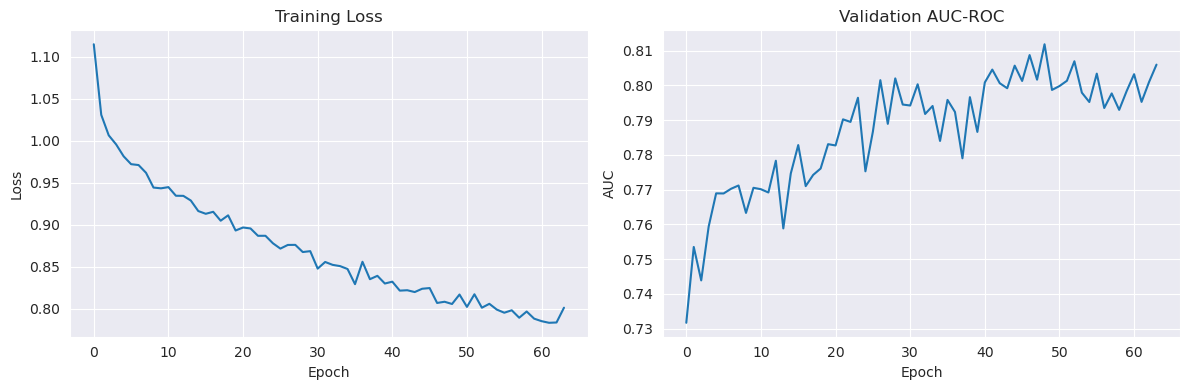

In [93]:
# Visualización de curvas de aprendizaje
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(val_aucs)
plt.title('Validation AUC-ROC')
plt.xlabel('Epoch')
plt.ylabel('AUC')

plt.tight_layout()
plt.show()